# 03 — CNN sobre log-mel-espectrogramas

Objetivo: um **primeiro modelo** (baseline) que passe a referência de **WA = 0.499** (prever sempre *Present*)
na **validação**. As variações (deltas, `fmax`, sobreposição, volume, `murmur_audible`...) ficam para depois.

| Passo | Decisão | Onde |
|---|---|---|
| Entrada | log-mel 64 × 313 por janela de 5 s, normalizado por banda (notebook 02) | `src/features.py` |
| Modelo | CNN 2D pequena: 4 blocos conv → *global average pooling* → 3 classes | este notebook |
| Desequilíbrio | pesos de classe na loss (inverso da frequência nas janelas do treino) | `src/training.py` |
| Rótulo da janela | o do paciente (opção (a)) | `src/features.py` |
| Previsão por paciente | média das janelas → gravação; *Present* se alguma gravação for *Present* | `src/training.py` |
| Paragem | *early stopping* pela WA do paciente na **validação** | `src/training.py` |

**O teste não é usado neste notebook.** Só no fim do projeto, com o modelo escolhido.

In [1]:
import sys; sys.path.append("..")
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from src.data import ROOT
from src.metrics import CLASSES, weighted_accuracy, confusion_matrix
from src.features import build_features, fit_standardizer, standardize
from src.training import set_seed, encode_labels, class_weights, fit, predict_proba, patient_predictions

sns.set_theme(style="whitegrid")
RESULTS = ROOT / "results"
torch.set_num_threads(8)
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.15.0+cpu | threads: 8


## 1. Dados

Mesmo pré-processamento do notebook 02. As médias e desvios de cada banda mel vêm **só do treino**.
Demora ~1 min.

In [2]:
start = time.time()
X_train, meta_train = build_features("train", kind="mel")
X_val, meta_val = build_features("val", kind="mel")
stats = fit_standardizer(X_train, "mel")
X_train = standardize(X_train, stats)[:, None]   # canal: (n, 1, 64, 313)
X_val = standardize(X_val, stats)[:, None]
y_train = encode_labels(meta_train)
print(f"treino {X_train.shape}, validação {X_val.shape}  ({time.time() - start:.0f} s)")

weights = class_weights(meta_train)
print(pd.DataFrame({"janelas treino": meta_train["murmur"].value_counts().reindex(CLASSES),
                    "peso na loss": weights.numpy().round(2)}, index=CLASSES))

treino (11225, 1, 64, 313), validação (2431, 1, 64, 313)  (65 s)
         janelas treino  peso na loss
Present            2148          1.74
Unknown             539          6.94
Absent             8538          0.44


**Pesos de classe:** `peso = total de janelas / (3 × janelas da classe)`, ou seja, inversamente proporcional ao
número de janelas da classe. Assim *peso × número de janelas* é igual nas três classes (~3 742): no conjunto, as janelas
de cada classe contam o mesmo na loss, embora o *Absent* tenha 76% das janelas.
Sem pesos, o modelo baixaria a loss sobretudo a acertar no *Absent* (no limite, dizia sempre *Absent*).

Por janela, errar uma *Unknown* custa 6.94 / 0.44 ≈ **16×** errar uma *Absent*, e uma *Present* ≈ 4×.
Nota: a métrica oficial usa outros pesos (5/3/1 **por paciente**, com *Present* acima de *Unknown*). Aqui o
*Unknown* pesa mais por ser a classe com menos janelas. Usar pesos que imitem a métrica fica como experiência.

## 2. Modelo

CNN pequena, de propósito: só ~650 pacientes no treino e treino em CPU.

- 4 blocos `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`, com 16 → 32 → 64 → 128 filtros.
  As primeiras camadas apanham padrões locais (o "clique" de S1/S2, o ruído contínuo do sopro);
  as últimas, combinações maiores no tempo e na frequência.
- **Global average pooling**: a média de cada filtro em todo o espectrograma. Não importa *onde* na janela aparece o
  sopro, e evita uma camada densa enorme (menos parâmetros, menos *overfitting*).
- Dropout 0.3 antes da camada final.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, channels=(16, 32, 64, 128), dropout=0.3, n_classes=len(CLASSES)):
        super().__init__()
        blocks, c_in = [], 1
        for c_out in channels:
            blocks += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


set_seed()
model = SmallCNN()
print(model)
print(f"parâmetros: {sum(p.numel() for p in model.parameters()):,}")

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=Tr

## 3. Treino

Adam (lr 1e-3, *weight decay* 1e-4), batches de 64, até 40 épocas. Em cada época calcula-se a WA **do paciente**
na validação; o modelo final é o da melhor época e o treino pára se não melhorar em 8 épocas.

| Escolha | O que é | Porquê este valor |
|---|---|---|
| **Adam** | otimizador que adapta o passo de cada peso (média dos gradientes recentes + da sua magnitude) | converge depressa e quase sem afinação; escolha habitual para uma baseline |
| **lr = 1e-3** | tamanho base de cada passo | valor por omissão do Adam. Grande demais → oscila/diverge; pequeno demais → precisa de muito mais épocas |
| **weight decay = 1e-4** | puxa os pesos para zero em cada passo (como o L2 / *lambda* da ridge) | regularização fraca contra *overfitting*. (No `Adam` é L2 no gradiente; o `AdamW` é uma alternativa a testar) |
| **batch = 64** | nº de janelas usadas para cada passo do gradiente (~176 passos por época) | meio-termo entre gradiente estável (batch grande) e mais passos/mais ruído que ajuda a generalizar (pequeno) |
| **até 40 épocas** | 1 época = uma passagem por todas as janelas do treino, em ordem aleatória | é só o máximo; normalmente pára antes |
| **early stopping (paciência 8)** | fica o modelo da época com maior WA na validação; pára se 8 épocas seguidas não a melhorarem | com o tempo a rede decora o treino (*overfitting*): a loss de treino desce mas a validação piora |

**Porquê a WA e não a loss da validação?** A WA é a métrica que interessa e é **por paciente**; a loss é por janela e
com pesos de classe diferentes. Nem sempre melhoram juntas.
**Porquê a validação e não o teste?** Escolher a época é uma decisão; feita com o teste, este deixava de ser uma
estimativa honesta (regra do guião).

**Ressalva:** a validação tem só 142 pacientes e a WA dá peso 5 aos 27 *Present*: um único *Present* a mais ou a
menos muda a WA em ~1.4 pontos. A curva da WA vai ser ruidosa e a "melhor época" tem alguma sorte à mistura.

Nenhum destes valores foi afinado: são os habituais para uma primeira baseline.

In [4]:
history = fit(model, X_train, y_train, X_val, meta_val, weights, epochs=40, patience=8)
torch.save(model.state_dict(), RESULTS / "cnn_baseline.pt")   # *.pt está no .gitignore

C:\Users\rfrei\PycharmProjects\Murmurs-Detection\notebooks\..\src\training.py:100: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  X_train_t, y_train_t = torch.as_tensor(X_train), torch.as_tensor(y_train)


época  1  loss treino 0.877  loss val 0.982  WA val 0.474  (116 s)


época  2  loss treino 0.778  loss val 0.999  WA val 0.496  (93 s)


época  3  loss treino 0.736  loss val 0.944  WA val 0.522  (92 s)


época  4  loss treino 0.713  loss val 1.063  WA val 0.600  (92 s)


época  5  loss treino 0.692  loss val 0.882  WA val 0.615  (94 s)


... (24 outputs left out)

época 30  loss treino 0.326  loss val 1.507  WA val 0.670  (102 s)


época 31  loss treino 0.265  loss val 1.288  WA val 0.744  (108 s)


época 32  loss treino 0.254  loss val 1.624  WA val 0.667  (109 s)


época 33  loss treino 0.235  loss val 2.392  WA val 0.707  (109 s)
early stopping: sem melhoria há 8 épocas
melhor época: 25 (WA val 0.759)


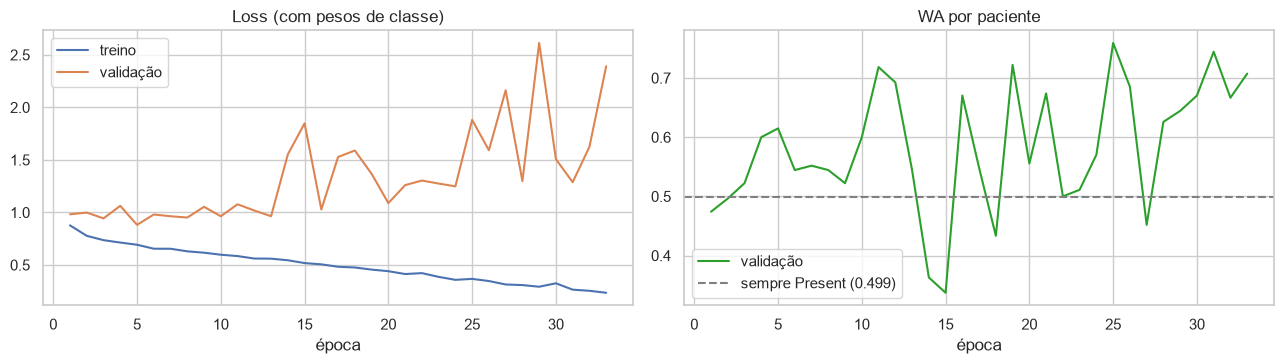

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(history["epoch"], history["train_loss"], label="treino")
axes[0].plot(history["epoch"], history["val_loss"], label="validação")
axes[0].set_title("Loss (com pesos de classe)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(history["epoch"], history["val_wa"], color="tab:green", label="validação")
axes[1].axhline(0.499, color="gray", ls="--", label="sempre Present (0.499)")
axes[1].set_title("WA por paciente"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.savefig(RESULTS / "cnn_baseline_treino.png", dpi=120); plt.show()

## 4. Resultados na validação

Matriz como no guião: **linhas = previsto, colunas = verdadeiro**.

validação: WA = 0.759  |  accuracy = 0.768  (142 pacientes)


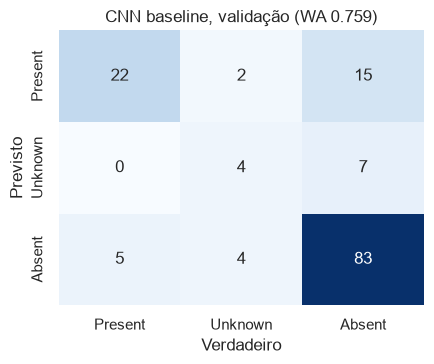

In [6]:
probs_val = predict_proba(model, X_val)
patients_val = patient_predictions(meta_val, probs_val)
wa = weighted_accuracy(patients_val["murmur"], patients_val["pred"])
acc = (patients_val["murmur"] == patients_val["pred"]).mean()
print(f"validação: WA = {wa:.3f}  |  accuracy = {acc:.3f}  ({len(patients_val)} pacientes)")

cm = confusion_matrix(patients_val["murmur"], patients_val["pred"])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"CNN baseline, validação (WA {wa:.3f})")
plt.tight_layout(); plt.savefig(RESULTS / "cnn_baseline_cm_val.png", dpi=120); plt.show()

### Por janela e por gravação

Para perceber **onde** se perde: a WA do paciente depende de três níveis.

In [7]:
win = meta_val.assign(pred=np.array(CLASSES)[probs_val.argmax(1)])
print(f"accuracy por janela: {(win['murmur'] == win['pred']).mean():.3f}")
print("matriz por janela (linhas = previsto):")
print(confusion_matrix(win["murmur"], win["pred"]))

# Present: a CNN acerta mais nas gravações onde o sopro é audível?
present = win[win["murmur"] == "Present"]
print("\njanelas de pacientes Present previstas como Present:")
print(present.groupby("murmur_audible")["pred"].apply(lambda p: f"{(p == 'Present').mean():.1%}"))

accuracy por janela: 0.759
matriz por janela (linhas = previsto):


Verdadeiro  Present  Unknown  Absent
Previsto                            
Present         263       14     232
Unknown           3       20      61
Absent          189       88    1561

janelas de pacientes Present previstas como Present:
murmur_audible
False    18.4%
True     68.6%
Name: pred, dtype: str


## 5. Conclusões da baseline

Execução de **21/11/2026**: 33 épocas × ~95 s ≈ **55 min** em CPU. Histórico em `results/cnn_baseline_history.csv`,
pesos em `results/cnn_baseline.pt`, figuras `results/cnn_baseline_*.png`.

- **WA na validação = 0.759** (melhor época: 25), bem acima da referência de 0.499 (sempre *Present*).
  Accuracy 0.768.
- **Por classe (pacientes):** *Present* 22/27 (81%), *Unknown* 4/10 (40%), *Absent* 83/105 (79%).
  Só 5 pacientes *Present* foram dados como *Absent* (o erro mais grave). O *Unknown* é a classe mais difícil, como esperado.
- **Audível vs. não audível:** nas janelas de pacientes *Present*, 69% são previstas *Present* quando o sopro é audível
  naquele local e só 18% quando não é. A regra "basta uma gravação *Present*" é o que recupera estes pacientes.
- **Treino muito instável:** a WA da validação salta entre 0.34 e 0.76 de uma época para a seguinte
  (ex.: 0.759 na época 25, 0.452 na 27). A melhor época é o pico de uma curva ruidosa, por isso **0.759 é otimista**
  (a média das últimas 5 épocas é 0.686).
- **Overfitting a partir da época ~13:** a loss de treino desce sempre (0.88 → 0.24), a da validação sobe e oscila (~1.0 → 1.3–2.6).

As oscilações sugerem passos grandes demais perto do ótimo → **experiência 1: baixar o lr quando a validação estagna.**

## 6. Experiência 1: `ReduceLROnPlateau`

Tudo igual à baseline (mesma seed, dados, modelo, pesos de classe, early stopping pela WA com paciência 8), exceto o lr:

- começa em 1e-3 e é **multiplicado por 0.3** quando a **loss da validação** não desce durante **3 épocas**
  (mínimo 1e-5);
- o scheduler usa a loss e não a WA porque a loss é mais suave (usa as 2 431 janelas, não 142 pacientes);
  a WA continua a decidir a melhor época e o early stopping;
- paciência do scheduler (3) < paciência do early stopping (8): quando estagna, primeiro tenta-se um lr menor,
  e só se nem isso ajudar é que o treino pára.

**O que se espera:** curvas mais estáveis nas últimas épocas e uma WA final menos dependente da sorte.
Para comparar não basta a melhor WA: olhar também para a **média das últimas 5 épocas**.

In [4]:
from src.training import log_experiment

set_seed()
model_plateau = SmallCNN()
history_plateau = fit(model_plateau, X_train, y_train, X_val, meta_val, weights, epochs=40, patience=8,
                      lr_plateau={"factor": 0.3, "patience": 3, "min_lr": 1e-5})
torch.save(model_plateau.state_dict(), RESULTS / "cnn_plateau.pt")

C:\Users\rfrei\PycharmProjects\Murmurs-Detection\notebooks\..\src\training.py:135: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  X_train_t, y_train_t = torch.as_tensor(X_train), torch.as_tensor(y_train)


época  1  lr 1.0e-03  loss treino 0.877  loss val 0.982  WA val 0.474  (91 s)


época  2  lr 1.0e-03  loss treino 0.778  loss val 0.999  WA val 0.496  (90 s)


época  3  lr 1.0e-03  loss treino 0.736  loss val 0.944  WA val 0.522  (90 s)


época  4  lr 1.0e-03  loss treino 0.713  loss val 1.063  WA val 0.600  (91 s)


época  5  lr 1.0e-03  loss treino 0.692  loss val 0.882  WA val 0.615  (91 s)


... (10 outputs left out)

época 16  lr 9.0e-05  loss treino 0.476  loss val 0.940  WA val 0.674  (91 s)


época 17  lr 9.0e-05  loss treino 0.474  loss val 1.023  WA val 0.633  (97 s)


época 18  lr 2.7e-05  loss treino 0.468  loss val 0.951  WA val 0.652  (92 s)


época 19  lr 2.7e-05  loss treino 0.468  loss val 0.951  WA val 0.644  (90 s)
early stopping: sem melhoria há 8 épocas
melhor época: 11 (WA val 0.719)


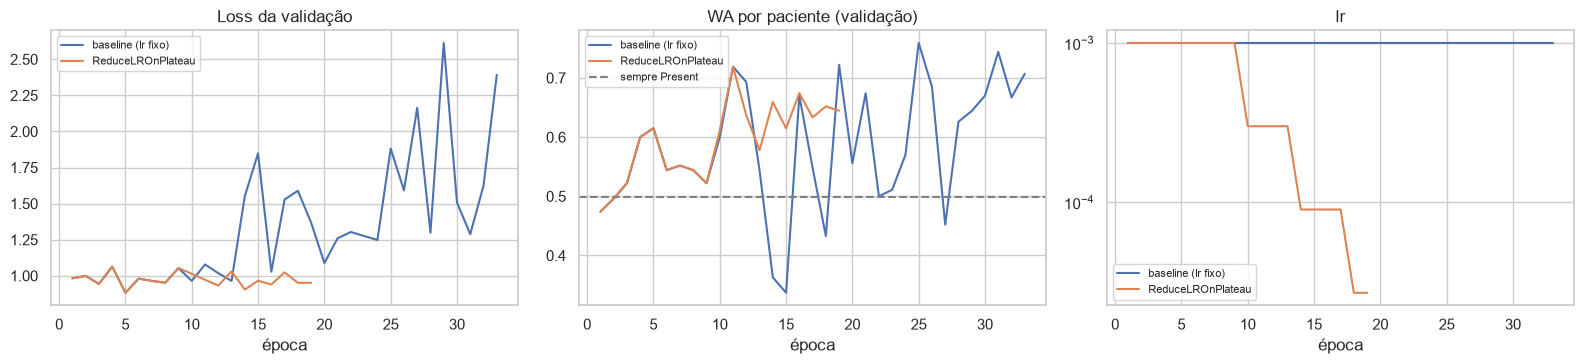

In [5]:
history_base = pd.read_csv(RESULTS / "cnn_baseline_history.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for h, name in [(history_base, "baseline (lr fixo)"), (history_plateau, "ReduceLROnPlateau")]:
    axes[0].plot(h["epoch"], h["val_loss"], label=name)
    axes[1].plot(h["epoch"], h["val_wa"], label=name)
    axes[2].plot(h["epoch"], h["lr"], label=name)
axes[0].set_title("Loss da validação"); axes[1].set_title("WA por paciente (validação)"); axes[2].set_title("lr")
axes[1].axhline(0.499, color="gray", ls="--", label="sempre Present")
axes[2].set_yscale("log")
for ax in axes: ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "cnn_plateau_vs_baseline.png", dpi=120); plt.show()

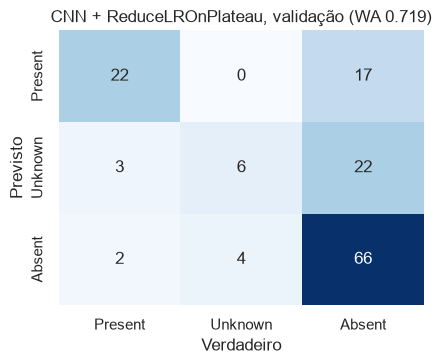

In [6]:
probs_plateau = predict_proba(model_plateau, X_val)
patients_plateau = patient_predictions(meta_val, probs_plateau)
wa_p = weighted_accuracy(patients_plateau["murmur"], patients_plateau["pred"])
cm = confusion_matrix(patients_plateau["murmur"], patients_plateau["pred"])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"CNN + ReduceLROnPlateau, validação (WA {wa_p:.3f})")
plt.tight_layout(); plt.savefig(RESULTS / "cnn_plateau_cm_val.png", dpi=120); plt.show()

### Registo das experiências

Cada experiência fica numa linha de `results/experiencias.csv` (resumo) e o histórico em `results/<nome>_history.csv`.
A baseline é registada a partir dos pesos guardados (`cnn_baseline.pt`), sem treinar de novo.

In [7]:
model_base = SmallCNN()
model_base.load_state_dict(torch.load(RESULTS / "cnn_baseline.pt"))
patients_base = patient_predictions(meta_val, predict_proba(model_base, X_val))

log_experiment("cnn_baseline", "CNN 4 blocos, Adam lr 1e-3 fixo, wd 1e-4, batch 64, pesos de classe, ES WA pac. 8",
               history_base, patients_base)
log = log_experiment("cnn_plateau", "baseline + ReduceLROnPlateau na loss val (factor 0.3, patience 3, min 1e-5)",
                     history_plateau, patients_plateau)
log

,experiencia,data,descricao,val_wa,val_accuracy,recall_Present,recall_Unknown,recall_Absent,melhor_epoca,epocas,wa_media_ultimas_5,minutos
0,cnn_baseline,2026-11-21,"CNN 4 blocos, Adam lr 1e-3 fixo, wd 1e-4, batc...",0.759,0.768,0.815,0.4,0.790,25,33,0.686,53.9
1,cnn_plateau,2026-11-21,baseline + ReduceLROnPlateau na loss val (fact...,0.719,0.662,0.815,0.6,0.629,11,19,0.644,29.0


### Conclusões da experiência 1

Execução de **21/11/2026**: 19 épocas, **29 min**. Histórico em `results/cnn_plateau_history.csv`.

| | Baseline (lr fixo) | `ReduceLROnPlateau` |
|---|---|---|
| WA val, melhor época | **0.759** (ép. 25) | 0.719 (ép. 11) |
| WA val, média das últimas 5 | **0.686** | 0.644 |
| Present / Unknown / Absent | 22/27 · 4/10 · **83/105** | 22/27 · **6/10** · 66/105 |
| Épocas / tempo | 33 / 54 min | 19 / 29 min |

- **Reprodutível:** as 9 primeiras épocas são iguais às da baseline, número a número (mesma seed, mesmo lr). A diferença
  vem só do scheduler.
- **Ficou mais estável, como esperado:** depois das reduções do lr a WA fica entre 0.58 e 0.67 (na baseline saltava
  entre 0.34 e 0.76) e a loss da validação deixou de disparar (~0.9–1.0 em vez de até 2.6). O overfitting desapareceu.
- **Mas ficou pior:** estável num patamar mais baixo. Os 5 *Present* falhados mantêm-se; a diferença está nos *Absent*:
  22 passam a ser dados como *Unknown* (contra 7 na baseline).
- **Porquê:** o lr foi reduzido **cedo demais**. A loss da validação quase não desce desde a época 1 (~0.9–1.0), por isso
  o scheduler viu "planalto" logo na época 10 e reduziu-o três vezes em 9 épocas, até 2.7e-5. A rede quase deixou de
  aprender (a loss de treino fica em ~0.47, contra 0.24 na baseline). Com o pico de 0.719 na época 11 e sem novas
  melhorias, o early stopping parou na época 19.
- **Atenção ao ruído:** 0.759 vs. 0.719 são ~3 pacientes *Present*. Com uma só seed e 142 pacientes na validação,
  diferenças desta ordem não são conclusivas.

**Decisão:** o problema principal não é o lr, é a **generalização**. A loss da validação nunca melhora muito, nem na
baseline: a rede aprende o treino, mas isso pouco se transfere para pacientes novos. Não mantemos este scheduler
assim. Se o voltarmos a usar, deve ser mais "paciente" (ex.: `patience` 5–6) e só depois de atacar a generalização:
- **mais dados:** sobreposição de 50% nas janelas do treino;
- **data augmentation:** máscaras no tempo/frequência do espectrograma (SpecAugment), pequenos deslocamentos;
- **rótulo `murmur_audible`:** hoje, as janelas *Present* sem sopro audível ensinam a rede a chamar *Present* a sons normais.